# Proyek Analisis Data: Air Quality Dataset
- **Nama:** Nindy Viviva Asri
- **Email:** nnindy806@gmail.com
- **ID Dicoding:** DS296B6X1381

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana tren rata-rata konsentrasi PM2.5 secara bulanan dan tahunan di Beijing selama periode Maret 2013–Februari 2017, serta pada tahun dan bulan apa rata-rata konsentrasi tertinggi terjadi, sehingga periode prioritas peningkatan pemantauan kualitas udara dapat ditentukan?
- **Pertanyaan 2:** Stasiun pemantauan mana yang memiliki rata-rata konsentrasi PM2.5 tertinggi di Beijing selama periode Maret 2013–Februari 2017, dan berapa selisihnya (µg/m³) dibandingkan stasiun lainnya, sehingga stasiun prioritas pemantauan dapat ditentukan?


## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os

## Data Wrangling

### Gathering Data

#### Load df Air Quality Dataset

In [2]:
from google.colab import files

uploaded = files.upload()

Saving Air-quality-dataset.zip to Air-quality-dataset.zip


In [3]:
import zipfile

zip_path = "Air-quality-dataset.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("air_quality")

print("Dataset berhasil diekstrak.")

Dataset berhasil diekstrak.


In [4]:
# untuk memastikan file terbaca dan lihat nama filenya

import glob

csv_files = glob.glob("air_quality/**/*.csv", recursive=True)

print("Jumlah file CSV:", len(csv_files))

for file in csv_files:
    print(file)

Jumlah file CSV: 12
air_quality/PRSA_Data_20130301-20170228/PRSA_Data_Wanshouxigong_20130301-20170228.csv
air_quality/PRSA_Data_20130301-20170228/PRSA_Data_Changping_20130301-20170228.csv
air_quality/PRSA_Data_20130301-20170228/PRSA_Data_Guanyuan_20130301-20170228.csv
air_quality/PRSA_Data_20130301-20170228/PRSA_Data_Tiantan_20130301-20170228.csv
air_quality/PRSA_Data_20130301-20170228/PRSA_Data_Dongsi_20130301-20170228.csv
air_quality/PRSA_Data_20130301-20170228/PRSA_Data_Wanliu_20130301-20170228.csv
air_quality/PRSA_Data_20130301-20170228/PRSA_Data_Gucheng_20130301-20170228.csv
air_quality/PRSA_Data_20130301-20170228/PRSA_Data_Nongzhanguan_20130301-20170228.csv
air_quality/PRSA_Data_20130301-20170228/PRSA_Data_Shunyi_20130301-20170228.csv
air_quality/PRSA_Data_20130301-20170228/PRSA_Data_Aotizhongxin_20130301-20170228.csv
air_quality/PRSA_Data_20130301-20170228/PRSA_Data_Huairou_20130301-20170228.csv
air_quality/PRSA_Data_20130301-20170228/PRSA_Data_Dingling_20130301-20170228.csv


In [5]:
# menggabungkan 12 file

dataframes = []

for file in csv_files:
    temp_df = pd.read_csv(file)
    dataframes.append(temp_df)

df = pd.concat(dataframes, ignore_index=True)

print("Ukuran dataset:", df.shape)

Ukuran dataset: (420768, 18)


In [6]:
# Menampilkan 5 data pertama
df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,9.0,9.0,6.0,17.0,200.0,62.0,0.3,1021.9,-19.0,0.0,WNW,2.0,Wanshouxigong
1,2,2013,3,1,1,11.0,11.0,7.0,14.0,200.0,66.0,-0.1,1022.4,-19.3,0.0,WNW,4.4,Wanshouxigong
2,3,2013,3,1,2,8.0,8.0,NaN,16.0,200.0,59.0,-0.6,1022.6,-19.7,0.0,WNW,4.7,Wanshouxigong
3,4,2013,3,1,3,8.0,8.0,3.0,16.0,NaN,NaN,-0.7,1023.5,-20.9,0.0,NW,2.6,Wanshouxigong
4,5,2013,3,1,4,8.0,8.0,3.0,NaN,300.0,36.0,-0.9,1024.1,-21.7,0.0,WNW,2.5,Wanshouxigong


**Insight:** (Opsional)
- Dataset Air Quality terdiri dari 12 file CSV yang berisi data dari 12 stasiun pemantauan kualitas udara.
- Dataset berhasil digabungkan menjadi satu DataFrame dengan 420.768 baris dan 18 kolom.
- Data mencakup informasi waktu (year, month, day, hour), parameter kualitas udara seperti PM2.5, PM10, SO2, NO2, CO, dan O3, serta kondisi meteorologi seperti suhu, tekanan udara, arah angin, dan kecepatan angin.
- Pada beberapa kolom juga terlihat adanya nilai kosong (NaN), yang akan diperiksa lebih lanjut pada tahap Assessing Data.

### Assessing Data

#### Identifying Data Quality problem

In [7]:
# Melihat informasi struktur dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB


In [8]:
# Mengecek jumlah nilai kosong pada setiap kolom
df.isna().sum()

,0
No,0
year,0
month,0
day,0
hour,0
PM2.5,8739
PM10,6449
SO2,9021
NO2,12116
CO,20701


In [9]:
# Mengecek jumlah data duplikat
duplicates = df.duplicated().sum()
print("Jumlah data duplikat:", duplicates)

Jumlah data duplikat: 0


In [10]:
# Mengecek nilai minimum dan maksimum kolom numerik
df.describe().T[['min', 'max']]

,min,max
No,1.0000,35064.0
year,2013.0000,2017.0
month,1.0000,12.0
day,1.0000,31.0
hour,0.0000,23.0
PM2.5,2.0000,999.0
PM10,2.0000,999.0
SO2,0.2856,500.0
NO2,1.0265,290.0
CO,100.0000,10000.0


In [11]:
# Mengecek jumlah PM2.5 dengan nilai sangat tinggi
(df['PM2.5'] > 500).sum()

np.int64(933)

In [12]:
df.describe()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,412029.000000,414319.000000,411747.000000,408652.000000,400067.000000,407491.000000,420370.000000,420375.000000,420365.000000,420378.000000,420450.000000
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,79.793428,104.602618,15.830835,50.638586,1230.766454,57.372271,13.538976,1010.746982,2.490822,0.064476,1.729711
std,10122.116943,1.177198,3.448707,8.800102,6.922195,80.822391,91.772426,21.650603,35.127912,1160.182716,56.661607,11.436139,10.474055,13.793847,0.821004,1.246386
min,1.000000,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,1.026500,100.000000,0.214200,-19.900000,982.400000,-43.400000,0.000000,0.000000
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,20.000000,36.000000,3.000000,23.000000,500.000000,11.000000,3.100000,1002.300000,-8.900000,0.000000,0.900000
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,55.000000,82.000000,7.000000,43.000000,900.000000,45.000000,14.500000,1010.400000,3.100000,0.000000,1.400000
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,111.000000,145.000000,20.000000,71.000000,1500.000000,82.000000,23.300000,1019.000000,15.100000,0.000000,2.200000
max,35064.000000,2017.000000,12.000000,31.000000,23.000000,999.000000,999.000000,500.000000,290.000000,10000.000000,1071.000000,41.600000,1042.800000,29.100000,72.500000,13.200000


In [13]:
Q1 = df['PM2.5'].quantile(0.25)
Q3 = df['PM2.5'].quantile(0.75)

IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Batas bawah:", batas_bawah)
print("Batas atas:", batas_atas)

Q1: 20.0
Q3: 111.0
IQR: 91.0
Batas bawah: -116.5
Batas atas: 247.5


In [14]:
outlier_pm25 = df[df['PM2.5'] > batas_atas]

print("Jumlah outlier PM2.5:", len(outlier_pm25))

Jumlah outlier PM2.5: 19142


In [15]:
# Melihat seluruh kategori pada kolom arah angin
df['wd'].value_counts(dropna=False)

,count
wd,
NE,43335
ENE,34142
NW,32600
N,30869
E,29752
SW,28756
NNE,28232
NNW,25326
WNW,24375


**Steps to Take:**
- Memeriksa jumlah nilai kosong (missing value) pada setiap kolom.  
- Mengidentifikasi nilai ekstrem (outlier) pada variabel PM2.5 menggunakan metode Interquartile Range (IQR).  
- Memeriksa data duplikat dan konsistensi kategori pada kolom wd untuk memastikan tidak terdapat data yang tidak sesuai.

**Insight:** (Opsional)
- Ditemukan nilai kosong pada 12 kolom, terutama pada parameter kualitas udara seperti CO sebanyak 20.701, O3 sebanyak 13.277, dan NO2 sebanyak 12.116 data.
- Berdasarkan metode IQR, variabel PM2.5 memiliki batas atas outlier sebesar 247,5 dan ditemukan sebanyak 19.142 data yang berada di atas batas tersebut.Nilai ekstrem ini tidak langsung dihapus karena dapat merepresentasikan kondisi kualitas udara dengan konsentrasi polutan yang tinggi.
- Pemeriksaan data duplikat menunjukkan tidak terdapat data duplikat, sedangkan kategori pada kolom wd masih konsisten.

### Cleaning Data

#### Fixing Data Quality problem

In [16]:
# Membuat kolom datetime dari data tahun, bulan, hari, dan jam
df['datetime'] = pd.to_datetime(
    df[['year', 'month', 'day', 'hour']]
)

# Mengurutkan data berdasarkan stasiun dan waktu
df = df.sort_values(['station', 'datetime']).reset_index(drop=True)

# Melihat 5 data pertama
df[['station', 'datetime']].head()

,station,datetime
0,Aotizhongxin,2013-03-01 00:00:00
1,Aotizhongxin,2013-03-01 01:00:00
2,Aotizhongxin,2013-03-01 02:00:00
3,Aotizhongxin,2013-03-01 03:00:00
4,Aotizhongxin,2013-03-01 04:00:00


In [17]:
# Kolom numerik yang memiliki missing value
numeric_cols = [
    'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3',
    'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM'
]

# Mengisi missing value dengan interpolasi berdasarkan urutan waktu
df[numeric_cols] = (
    df.groupby('station')[numeric_cols]
      .transform(lambda x: x.interpolate(method='linear'))
)

In [18]:
# Mengecek kembali jumlah missing value
df.isna().sum()

,0
No,0
year,0
month,0
day,0
hour,0
PM2.5,0
PM10,0
SO2,0
NO2,22
CO,0


In [19]:
# Mengisi sisa missing value berdasarkan data terdekat
df['NO2'] = (
    df.groupby('station')['NO2']
      .transform(lambda x: x.ffill().bfill())
)

df['wd'] = (
    df.groupby('station')['wd']
      .transform(lambda x: x.ffill().bfill())
)

In [20]:
# Mengecek kembali missing value setelah proses cleaning
df.isna().sum()

,0
No,0
year,0
month,0
day,0
hour,0
PM2.5,0
PM10,0
SO2,0
NO2,0
CO,0


In [21]:
# Melihat statistik PM2.5 setelah proses cleaning
df['PM2.5'].describe()

,PM2.5
count,420768.000000
mean,79.839718
std,80.950217
min,2.000000
25%,20.000000
50%,55.000000
75%,111.000000
max,999.000000


In [22]:
# Menghitung jumlah outlier PM2.5 setelah cleaning
outlier_pm25 = df[df['PM2.5'] > 247.5]

print("Jumlah outlier PM2.5:", len(outlier_pm25))

Jumlah outlier PM2.5: 19612


**Insight:** (Opsional)
- Berdasarkan metode IQR, batas atas outlier PM2.5 adalah 247,5. Setelah proses penanganan missing value, terdapat 19.612 data yang berada di atas batas tersebut. Data outlier tetap dipertahankan karena nilai ekstrem pada PM2.5 dapat menunjukkan kondisi polusi udara yang tinggi dan masih relevan dengan tujuan analisis.
- Missing value pada parameter kualitas udara dan cuaca ditangani dengan interpolasi linear berdasarkan urutan waktu pada setiap stasiun. Sisa missing value (NO2 dan arah angin) diisi dengan nilai terdekat (forward/backward fill) pada stasiun yang sama, sehingga seluruh kolom tidak lagi memiliki nilai kosong.


## Exploratory Data Analysis (EDA)

### Statistik Deskriptif Parameter Kualitas Udara

In [23]:
# Melihat statistik deskriptif variabel kualitas udara
df[['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3']].describe()

,PM2.5,PM10,SO2,NO2,CO,O3
count,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000
mean,79.839718,104.910268,15.913090,50.599018,1235.682649,57.237872
std,80.950217,92.431422,21.896609,35.171921,1161.790893,57.135195
min,2.000000,2.000000,0.285600,1.026500,100.000000,0.214200
25%,20.000000,36.000000,3.000000,23.000000,500.000000,10.000000
50%,55.000000,82.000000,7.000000,43.000000,900.000000,44.000000
75%,111.000000,145.000000,20.000000,71.000000,1500.000000,82.000000
max,999.000000,999.000000,500.000000,290.000000,10000.000000,1071.000000


**Insight:** (Opsional)
- Berdasarkan statistik deskriptif, PM2.5 memiliki rata-rata sebesar 79,84, sedangkan PM10 memiliki rata-rata sebesar 104,91. Di antara parameter kualitas udara yang dianalisis, CO memiliki rata-rata sebesar 1.235,68 dan O3 sebesar 57,24. Nilai maksimum PM2.5 mencapai 999, yang menunjukkan adanya konsentrasi polutan yang sangat tinggi pada beberapa pengamatan. Hasil ini memberikan gambaran awal mengenai variasi kualitas udara dan menjadi dasar untuk eksplorasi lebih lanjut berdasarkan waktu dan stasiun pemantauan.

### Eksplorasi Pertanyaan 1: Pola PM2.5 Berdasarkan Waktu
Rata-rata PM2.5 dihitung per tahun, per bulan, dan per kombinasi tahun-bulan untuk melihat pola waktu serta menentukan periode dengan konsentrasi tertinggi.

In [24]:
# Rata-rata PM2.5 berdasarkan tahun, sekaligus jumlah bulan data pada tiap tahun
pm25_yearly = (
    df.groupby('year')
      .agg(rata_rata_pm25=('PM2.5', 'mean'), jumlah_bulan=('month', 'nunique'))
      .reset_index()
)

pm25_yearly


,year,rata_rata_pm25,jumlah_bulan
0,2013,79.768553,10
1,2014,86.183671,12
2,2015,79.306423,12
3,2016,72.078419,12
4,2017,92.407898,2


In [25]:
# Rata-rata PM2.5 berdasarkan bulan
pm25_monthly = df.groupby('month')['PM2.5'].mean()

pm25_monthly

,PM2.5
month,
1,93.760559
2,89.213391
3,94.594295
4,73.367153
5,63.541148
6,68.837547
7,71.401115
8,53.465479
9,61.281071


In [26]:
# Rata-rata PM2.5 berdasarkan tahun dan bulan
pm25_year_month = df.groupby(['year', 'month'])['PM2.5'].mean().reset_index()

# 10 periode tahun-bulan tertinggi, sekaligus jumlah data pada setiap periode
pm25_year_month_detail = (
    df.groupby(['year', 'month'])['PM2.5']
      .agg(['mean', 'count'])
      .reset_index()
      .sort_values('mean', ascending=False)
)

pm25_year_month_detail.head(10)


,year,month,mean,count
11,2014,2,153.808780,8064
33,2015,12,149.601759,8928
45,2016,12,128.733199,8928
19,2014,10,119.375728,8928
32,2015,11,114.757465,8640
46,2017,1,113.729839,8928
0,2013,3,104.571909,8928
3,2013,6,101.542242,8640
10,2014,1,98.390065,8928
44,2016,11,97.437384,8640


In [27]:
pm25_year_month_pivot = pm25_year_month.pivot(
    index='year',
    columns='month',
    values='PM2.5'
)

pm25_year_month_pivot

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2013,NaN,NaN,104.571909,62.207292,81.876512,101.542242,66.839665,60.588374,76.140304,91.765320,73.821007,78.159890
2014,98.390065,153.808780,95.227431,91.825231,62.177315,54.435571,89.148141,63.157616,66.250880,119.375728,87.279994,58.221890
2015,96.122711,93.078199,86.384123,71.839560,55.727503,60.668414,60.951501,44.303707,48.758218,70.132728,114.757465,149.601759
2016,66.799619,42.821959,92.193716,67.596528,54.383262,58.703962,68.665155,45.812220,53.974884,85.589662,97.437384,128.733199
2017,113.729839,68.801463,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Insight:**
- Di antara tahun dengan data 12 bulan penuh, rata-rata PM2.5 tertinggi terjadi pada **2014 (86,18)** dan terendah pada **2016 (72,08)**. Tahun 2013 (Maret–Desember, 79,77) dan 2017 (Januari–Februari, 92,41) tidak memiliki data 12 bulan penuh, sehingga tidak dibandingkan langsung dengan tahun lain.
- Secara bulanan, rata-rata tertinggi terjadi pada **Desember (103,68)** dan terendah pada **Agustus (53,47)**. Bulan Oktober–Maret cenderung lebih tinggi daripada bulan April–September.
- Berdasarkan kombinasi tahun-bulan, tiga periode tertinggi adalah **Februari 2014 (153,81)**, **Desember 2015 (149,60)**, dan **Desember 2016 (128,73)**.

### Eksplorasi Pertanyaan 2: Perbandingan Antarstasiun
Rata-rata PM2.5 dihitung untuk setiap stasiun, lalu dibandingkan dengan stasiun tertinggi untuk melihat besar selisihnya.

In [28]:
pm25_station = (
    df.groupby('station')['PM2.5']
      .agg(['mean', 'count'])
      .reset_index()
      .sort_values('mean', ascending=False)
)

pm25_station

,station,mean,count
3,Dongsi,86.144243,35064
7,Nongzhanguan,85.079472,35064
11,Wanshouxigong,85.067548,35064
5,Gucheng,84.074802,35064
10,Wanliu,83.467612,35064
4,Guanyuan,82.897522,35064
0,Aotizhongxin,82.540623,35064
9,Tiantan,82.033097,35064
8,Shunyi,79.437962,35064
1,Changping,70.986438,35064


In [29]:
pm25_station['difference_from_highest'] = (
    pm25_station['mean'].iloc[0] - pm25_station['mean']
)

pm25_station

,station,mean,count,difference_from_highest
3,Dongsi,86.144243,35064,0.000000
7,Nongzhanguan,85.079472,35064,1.064772
11,Wanshouxigong,85.067548,35064,1.076695
5,Gucheng,84.074802,35064,2.069442
10,Wanliu,83.467612,35064,2.676631
4,Guanyuan,82.897522,35064,3.246722
0,Aotizhongxin,82.540623,35064,3.603621
9,Tiantan,82.033097,35064,4.111147
8,Shunyi,79.437962,35064,6.706281
1,Changping,70.986438,35064,15.157806


**Insight:**
- **Dongsi (86,14)** memiliki rata-rata PM2.5 tertinggi, disusul Nongzhanguan (85,08) dan Wanshouxigong (85,07). Ketiganya hanya berselisih sekitar 1 poin.
- **Dingling (66,85)** memiliki rata-rata terendah, selisih **19,30** dari Dongsi. Changping dan Huairou juga relatif rendah (di bawah 71).
- Setiap stasiun memiliki jumlah data yang sama (35.064 jam), sehingga perbandingan antarstasiun dapat dianggap adil.

## Visualization & Explanatory Analysis

In [30]:
# Pengaturan tampilan visualisasi (dipakai oleh semua grafik di bawah)
WARNA_SOROT = '#d1495b'   # menonjolkan data yang menjadi jawaban pertanyaan
WARNA_BIASA = '#a9c1de'   # data pembanding
WARNA_TEKS = '#33415c'

nama_bulan = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
nama_bulan_penuh = {1: 'Januari', 2: 'Februari', 3: 'Maret', 4: 'April', 5: 'Mei', 6: 'Juni',
                    7: 'Juli', 8: 'Agustus', 9: 'September', 10: 'Oktober', 11: 'November', 12: 'Desember'}

def rapikan_axes(ax, grid_axis='y'):
    """Hapus garis tepi yang tidak perlu dan pakai grid tipis."""
    for sisi in ['top', 'right']:
        ax.spines[sisi].set_visible(False)
    ax.grid(axis=grid_axis, alpha=0.3)
    ax.set_axisbelow(True)


### Pertanyaan 1:

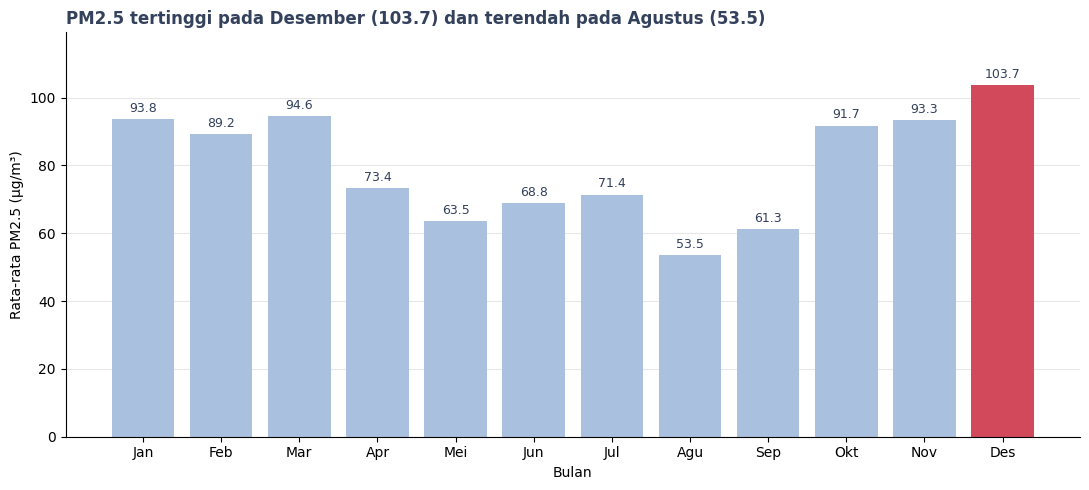

In [31]:
# Rata-rata PM2.5 per bulan: menonjolkan bulan tertinggi
bulan_tertinggi = pm25_monthly.idxmax()
bulan_terendah = pm25_monthly.idxmin()
warna = [WARNA_SOROT if m == bulan_tertinggi else WARNA_BIASA for m in pm25_monthly.index]

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar([nama_bulan[m - 1] for m in pm25_monthly.index], pm25_monthly.values, color=warna)
ax.bar_label(bars, fmt='%.1f', padding=3, fontsize=9, color=WARNA_TEKS)
ax.set_title(f'PM2.5 tertinggi pada {nama_bulan_penuh[bulan_tertinggi]} ({pm25_monthly.max():.1f}) '
             f'dan terendah pada {nama_bulan_penuh[bulan_terendah]} ({pm25_monthly.min():.1f})',
             loc='left', fontsize=12, fontweight='bold', color=WARNA_TEKS)
ax.set_xlabel('Bulan')
ax.set_ylabel('Rata-rata PM2.5 (µg/m³)')
ax.set_ylim(0, pm25_monthly.max() * 1.15)
rapikan_axes(ax)
plt.tight_layout()
plt.show()


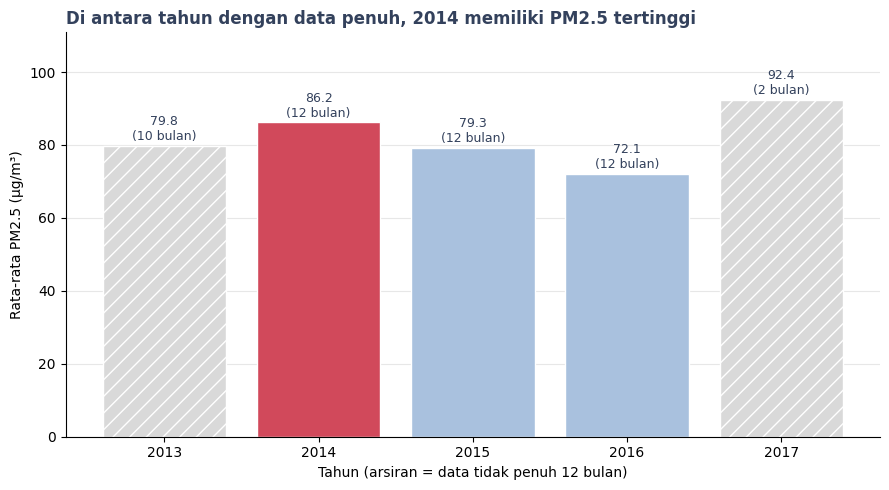

In [32]:
# Rata-rata PM2.5 per tahun: tahun tidak penuh diberi arsiran agar tidak salah dibandingkan
penuh = pm25_yearly[pm25_yearly['jumlah_bulan'] == 12]
tahun_puncak = int(penuh.loc[penuh['rata_rata_pm25'].idxmax(), 'year'])

fig, ax = plt.subplots(figsize=(9, 5))
for _, r in pm25_yearly.iterrows():
    tahun = str(int(r['year']))
    if r['jumlah_bulan'] < 12:
        warna, arsir = '#d9d9d9', '//'
    elif int(r['year']) == tahun_puncak:
        warna, arsir = WARNA_SOROT, None
    else:
        warna, arsir = WARNA_BIASA, None
    ax.bar(tahun, r['rata_rata_pm25'], color=warna, hatch=arsir, edgecolor='white')
    ax.text(tahun, r['rata_rata_pm25'] + 1.5,
            f"{r['rata_rata_pm25']:.1f}\n({int(r['jumlah_bulan'])} bulan)",
            ha='center', fontsize=9, color=WARNA_TEKS)

ax.set_title(f'Di antara tahun dengan data penuh, {tahun_puncak} memiliki PM2.5 tertinggi',
             loc='left', fontsize=12, fontweight='bold', color=WARNA_TEKS)
ax.set_xlabel('Tahun (arsiran = data tidak penuh 12 bulan)')
ax.set_ylabel('Rata-rata PM2.5 (µg/m³)')
ax.set_ylim(0, pm25_yearly['rata_rata_pm25'].max() * 1.2)
rapikan_axes(ax)
plt.tight_layout()
plt.show()


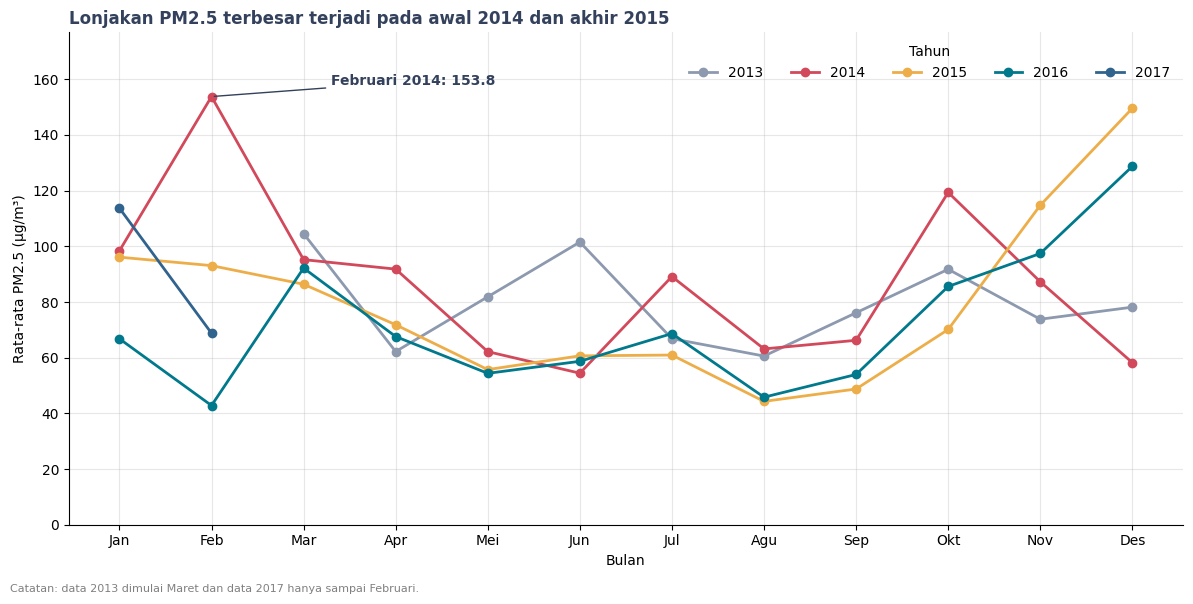

In [33]:
# Pola bulanan pada setiap tahun, dengan anotasi pada periode tertinggi
palet = ['#8d99ae', '#d1495b', '#edae49', '#00798c', '#30638e']
puncak = pm25_year_month.loc[pm25_year_month['PM2.5'].idxmax()]

fig, ax = plt.subplots(figsize=(12, 6))
for warna, tahun in zip(palet, pm25_year_month_pivot.index):
    ax.plot(pm25_year_month_pivot.columns, pm25_year_month_pivot.loc[tahun],
            marker='o', linewidth=2, color=warna, label=str(tahun))

ax.annotate(f"{nama_bulan_penuh[int(puncak['month'])]} {int(puncak['year'])}: {puncak['PM2.5']:.1f}",
            xy=(puncak['month'], puncak['PM2.5']),
            xytext=(puncak['month'] + 1.3, puncak['PM2.5'] + 4),
            arrowprops=dict(arrowstyle='-', color=WARNA_TEKS),
            fontsize=10, fontweight='bold', color=WARNA_TEKS)

ax.set_title('Lonjakan PM2.5 terbesar terjadi pada awal 2014 dan akhir 2015',
             loc='left', fontsize=12, fontweight='bold', color=WARNA_TEKS)
ax.set_xlabel('Bulan')
ax.set_ylabel('Rata-rata PM2.5 (µg/m³)')
ax.set_xticks(range(1, 13), nama_bulan)
ax.set_ylim(0, puncak['PM2.5'] * 1.15)
ax.legend(title='Tahun', frameon=False, ncol=5, loc='upper right')
rapikan_axes(ax, 'both')
plt.figtext(0.01, 0.005, 'Catatan: data 2013 dimulai Maret dan data 2017 hanya sampai Februari.',
            fontsize=8, color='gray')
plt.tight_layout(rect=(0, 0.02, 1, 1))
plt.show()


**Insight:**

Berdasarkan visualisasi, rata-rata konsentrasi PM2.5 di Beijing menunjukkan **tren yang berfluktuasi secara bulanan dan tahunan** selama periode pengamatan. Secara bulanan, rata-rata PM2.5 tertinggi terjadi pada **Desember sebesar 103,68**, sedangkan terendah terjadi pada **Agustus sebesar 53,47**. Berdasarkan kombinasi tahun dan bulan, konsentrasi tertinggi terjadi pada **Februari 2014 sebesar 153,81**, diikuti Desember 2015 sebesar 149,60.

Secara tahunan, rata-rata PM2.5 tertinggi berdasarkan data yang tersedia terdapat pada **2017 sebesar 92,41**. Namun, data tahun 2017 hanya tersedia hingga **Februari**, sehingga hasil tersebut tidak dapat dibandingkan secara langsung dengan tahun-tahun yang memiliki data lebih lengkap. Dengan demikian, **Februari 2014 merupakan periode tahun-bulan dengan rata-rata konsentrasi PM2.5 tertinggi** dalam data yang dianalisis.

### Pertanyaan 2:

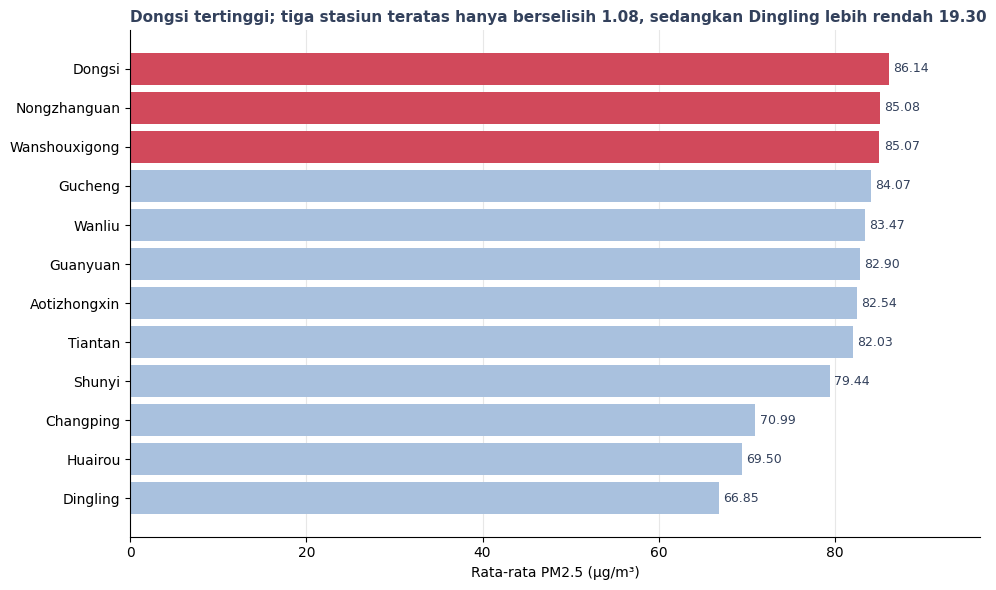

In [34]:
# Rata-rata PM2.5 per stasiun: tiga stasiun tertinggi ditonjolkan
urut = pm25_station.sort_values('mean', ascending=True)
top3 = pm25_station.head(3)['station'].tolist()
warna = [WARNA_SOROT if s in top3 else WARNA_BIASA for s in urut['station']]
selisih_top3 = pm25_station['mean'].iloc[0] - pm25_station['mean'].iloc[2]
terendah = pm25_station.iloc[-1]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(urut['station'], urut['mean'], color=warna)
ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=9, color=WARNA_TEKS)
ax.set_title(f"{pm25_station['station'].iloc[0]} tertinggi; tiga stasiun teratas hanya berselisih "
             f"{selisih_top3:.2f}, sedangkan {terendah['station']} lebih rendah "
             f"{terendah['difference_from_highest']:.2f}",
             loc='left', fontsize=11, fontweight='bold', color=WARNA_TEKS)
ax.set_xlabel('Rata-rata PM2.5 (µg/m³)')
ax.set_xlim(0, urut['mean'].max() * 1.12)
rapikan_axes(ax, 'x')
plt.tight_layout()
plt.show()


**Insight:** (Opsional)
- Berdasarkan visualisasi, Dongsi memiliki rata-rata konsentrasi PM2.5 tertinggi selama periode pengamatan, yaitu sebesar 86,14. Nilai tersebut hanya berbeda 1,06 dari Nongzhanguan sebagai stasiun dengan rata-rata tertinggi kedua dan 1,08 dari Wanshouxigong. Sementara itu, Dingling memiliki rata-rata PM2.5 terendah sebesar 66,85, sehingga terdapat perbedaan sebesar 19,30 dibandingkan Dongsi. Hal ini menunjukkan bahwa konsentrasi PM2.5 relatif tinggi pada beberapa stasiun, tetapi terdapat perbedaan yang cukup terlihat antara stasiun dengan rata-rata tertinggi dan terendah.

## Analisis Lanjutan (Opsional)

Pada tahap ini diterapkan teknik **Binning (manual grouping)** untuk mengelompokkan stasiun berdasarkan rata-rata PM2.5.

- **Tujuan:** menyederhanakan perbandingan 12 stasiun menjadi tiga kategori (*Rendah*, *Sedang*, *Tinggi*) agar stasiun yang perlu diprioritaskan dalam pemantauan lebih mudah dikenali.
- **Cara kerja:** batas kategori ditentukan dari kuartil rata-rata PM2.5 antarstasiun menggunakan `pd.cut()`. Kategori *Rendah* untuk nilai ≤ Q1, *Sedang* untuk nilai di antara Q1 dan Q3, dan *Tinggi* untuk nilai > Q3.
- **Catatan:** kategori bersifat relatif (membandingkan stasiun satu dengan yang lain), bukan standar baku mutu udara. Teknik ini tidak menggunakan algoritma machine learning.

In [35]:
q1 = pm25_station['mean'].quantile(0.25)
q3 = pm25_station['mean'].quantile(0.75)

bins = [-float('inf'), q1, q3, float('inf')]
labels = ['Rendah', 'Sedang', 'Tinggi']

pm25_station['kategori_pm25'] = pd.cut(
    pm25_station['mean'],
    bins=bins,
    labels=labels
)

pm25_station[['station', 'mean', 'kategori_pm25']]

,station,mean,kategori_pm25
3,Dongsi,86.144243,Tinggi
7,Nongzhanguan,85.079472,Tinggi
11,Wanshouxigong,85.067548,Tinggi
5,Gucheng,84.074802,Sedang
10,Wanliu,83.467612,Sedang
4,Guanyuan,82.897522,Sedang
0,Aotizhongxin,82.540623,Sedang
9,Tiantan,82.033097,Sedang
8,Shunyi,79.437962,Sedang
1,Changping,70.986438,Rendah


In [36]:
kategori_count = (
    pm25_station['kategori_pm25']
    .value_counts()
    .reindex(['Rendah', 'Sedang', 'Tinggi'])
)

kategori_count

,count
kategori_pm25,
Rendah,3
Sedang,6
Tinggi,3


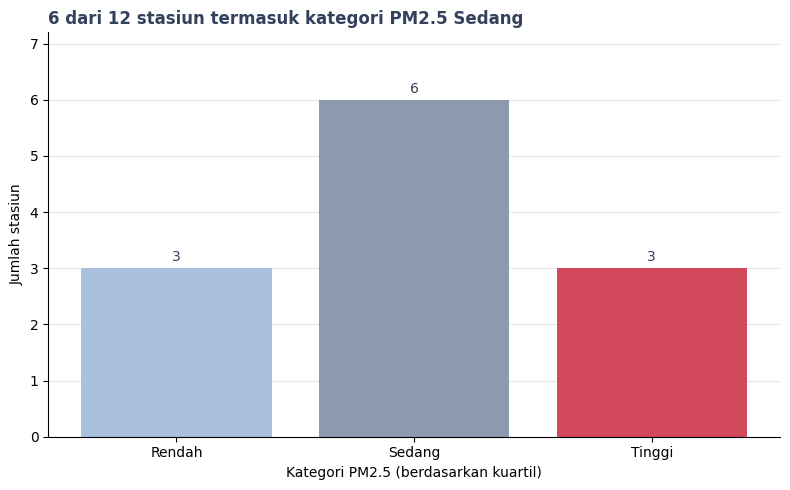

In [37]:
# Distribusi stasiun berdasarkan kategori PM2.5
warna_kategori = {'Rendah': WARNA_BIASA, 'Sedang': '#8d99ae', 'Tinggi': WARNA_SOROT}

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(kategori_count.index, kategori_count.values,
              color=[warna_kategori[k] for k in kategori_count.index])
ax.bar_label(bars, padding=3, fontsize=10, color=WARNA_TEKS)
ax.set_title(f"{int(kategori_count['Sedang'])} dari {int(kategori_count.sum())} stasiun "
             f"termasuk kategori PM2.5 Sedang",
             loc='left', fontsize=12, fontweight='bold', color=WARNA_TEKS)
ax.set_xlabel('Kategori PM2.5 (berdasarkan kuartil)')
ax.set_ylabel('Jumlah stasiun')
ax.set_ylim(0, kategori_count.max() * 1.2)
rapikan_axes(ax)
plt.tight_layout()
plt.show()


**Insight:** (Opsional)
- Berdasarkan hasil binning, sebanyak 6 dari 12 stasiun (50%) termasuk dalam kategori PM2.5 Sedang, sedangkan masing-masing 3 stasiun (25%) termasuk kategori Rendah dan Tinggi. Stasiun yang masuk kategori Tinggi adalah Dongsi, Nongzhanguan, dan Wanshouxigong, sedangkan kategori Rendah terdiri dari Changping, Huairou, dan Dingling. Pengelompokan ini membantu mengidentifikasi stasiun yang perlu mendapatkan prioritas pemantauan lebih tinggi berdasarkan rata-rata konsentrasi PM2.5.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Tren konsentrasi PM2.5 berdasarkan waktu menunjukkan pola yang berfluktuasi secara bulanan dan tahunan. Rata-rata PM2.5 tertinggi berdasarkan kombinasi tahun dan bulan terjadi pada Februari 2014 sebesar 153,81. Secara bulanan, Desember memiliki rata-rata tertinggi sebesar 103,68. Rata-rata tahunan tertinggi terdapat pada 2017 sebesar 92,41, tetapi data tahun 2017 hanya tersedia hingga Februari sehingga tidak dapat dibandingkan secara langsung dengan tahun penuh.
- **Conclusion pertanyaan 2:** Dongsi merupakan stasiun dengan rata-rata konsentrasi PM2.5 tertinggi selama periode pengamatan, yaitu 86,14. Nilainya hanya berbeda 1,06 dari Nongzhanguan, tetapi memiliki selisih 19,30 dibandingkan Dingling yang memiliki rata-rata terendah sebesar 66,85.

**Rekomendasi Action Item:**
1. Prioritaskan pemantauan dan evaluasi kualitas udara pada stasiun berkategori Tinggi, yaitu Dongsi, Nongzhanguan, dan Wanshouxigong.
2. Perkuat kesiapsiagaan pada periode Oktober–Maret, terutama bulan Desember yang memiliki rata-rata PM2.5 bulanan tertinggi (103,68).
3. Selidiki penyebab lonjakan pada Februari 2014 (153,81) dan Desember 2015 (149,60), misalnya dengan menghubungkannya ke data cuaca seperti kecepatan dan arah angin.

In [38]:
df.to_csv('main_data.csv', index=False)

print("File main_data.csv berhasil dibuat.")

File main_data.csv berhasil dibuat.
